# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import mPv4gerDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [9]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/m_pv4ger/data/classification_v0.8.1/pv4ger_classification",
    "csv_file": "/home/dragik/data/FAIR_EO/m_pv4ger/label_map.json"
}
dataset = mPv4gerDataset(dataset_config)
len(dataset)

13812

## Show images from the dataset

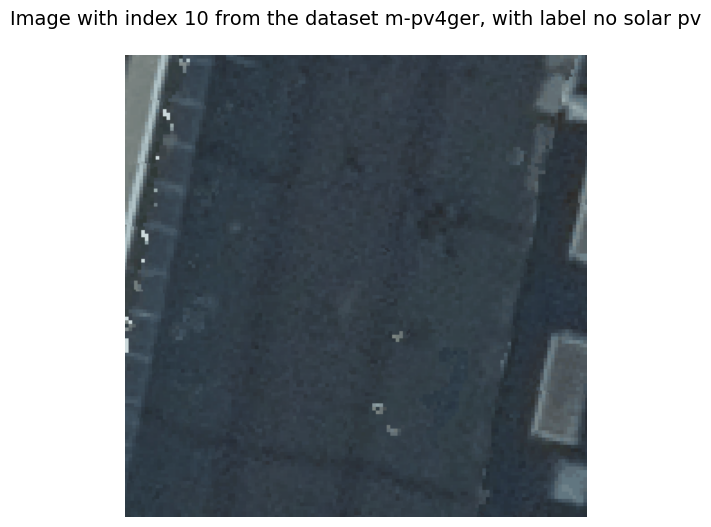

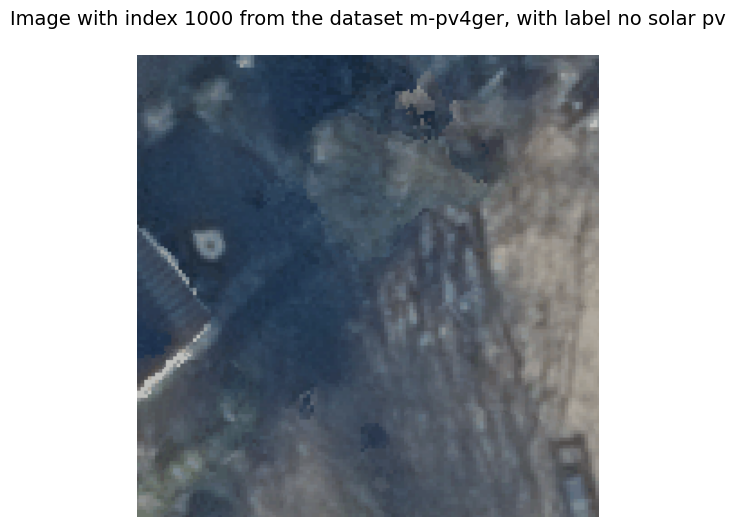

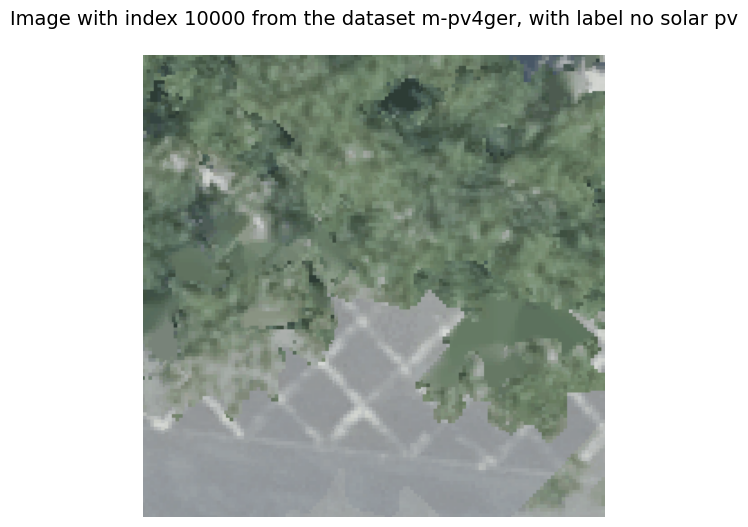

In [18]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(1000)
fig3 = dataset.show_image(10000)

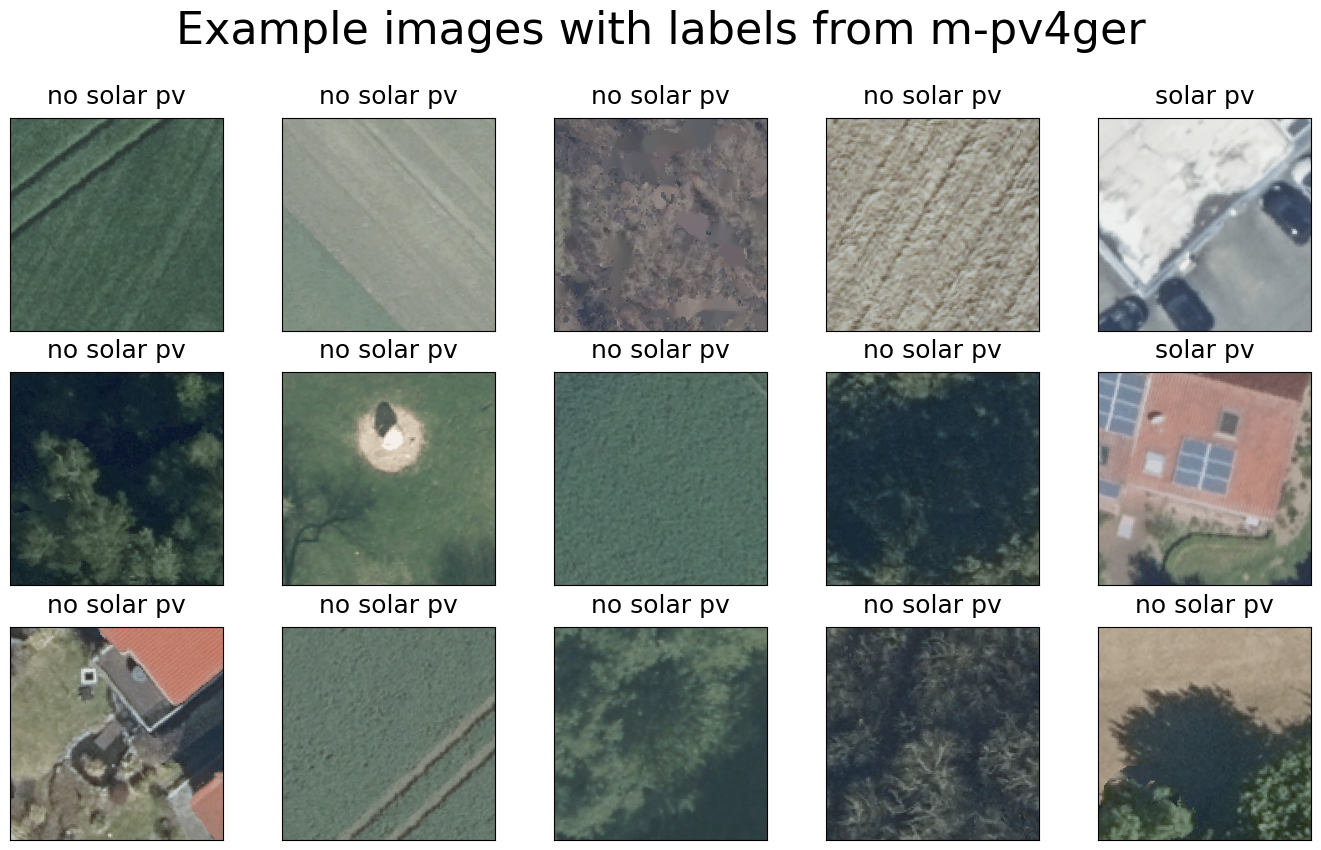

In [19]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [10]:
dataset.data_distribution_table()

,Number of samples
no solar pv,11692
solar pv,2120


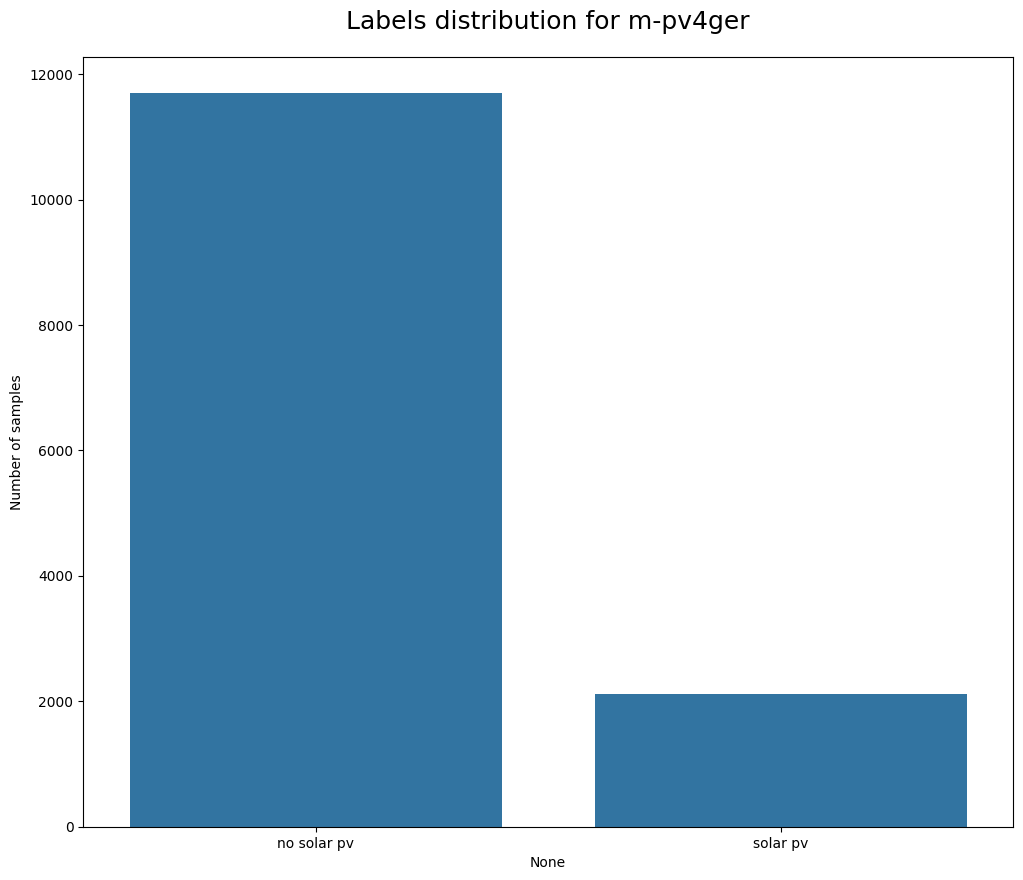

In [11]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [15]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/m_pv4ger/data/classification_v0.8.1/pv4ger_classification",
    "csv_file": "/home/dragik/data/FAIR_EO/m_pv4ger/label_map.json",
    "mode": "train"
}

train_dataset = mPv4gerDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/m_pv4ger/data/classification_v0.8.1/pv4ger_classification",
    "csv_file": "/home/dragik/data/FAIR_EO/m_pv4ger/label_map.json",
    "mode": "val",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = mPv4gerDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(8287, 2762)

## Setup and create the model for training

In [16]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/m_pv4ger/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2026-04-29 07:17:09,098 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2026-04-29 07:17:09,420 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [17]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2026-04-29 07:17:11,491 INFO Starting training.
training: 100%|██████████| 259/259 [01:04<00:00,  4.00it/s]
2026-04-29 07:18:16,265 INFO epoch: 1, time: 65, loss:  0.15667
testing on train set: 100%|██████████| 259/259 [00:23<00:00, 10.95it/s]
2026-04-29 07:18:42,277 INFO Accuracy:0.9583685290213587, Precision Micro:0.9583685290213587, Precision Macro:0.9700172426749096, Precision Weighted:0.959520499767943, Precision per Class:[0.95495986 0.98507463], Recall Micro:0.9583685290213587, Recall Macro:0.8671320406655516, Recall Weighted:0.9583685290213588, Recall per Class:[0.9980091  0.73625498], F1_score Micro:0.9583685290213582, F1_score Macro:0.9093456358809036, F1_score Weighted:0.9558184375993819, F1_score per Class:[0.97601001 0.84268126]
testing on validation set: 100%|██████████| 87/87 [00:08<00:00, 10.80it/s]
2026-04-29 07:18:50,344 INFO Accuracy:0.9590876176683563, Precision Micro:0.9590876176683563, Precision Macro:0.9741259326557419, Precision Weighted:0.9606053735328239, Prec

0.03359659106297686

## Test the model

In [18]:
test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/m_pv4ger/data/classification_v0.8.1/pv4ger_classification",
    "csv_file": "/home/dragik/data/FAIR_EO/m_pv4ger/label_map.json",
    "mode": "test",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = mPv4gerDataset(test_dataset_config)
model_path = "/home/dragik/data/FAIR_EO/experiments/m_pv4ger/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2026-04-29 07:33:59,033 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/m_pv4ger/checkpoint.pth.tar
2026-04-29 07:33:59,384 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/m_pv4ger/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 173/173 [00:08<00:00, 19.78it/s]


[{'Accuracy': 0.9659790083242852},
 {'Precision Micro': 0.9659790083242852,
  'Precision Macro': 0.9490937452825441,
  'Precision Weighted': 0.9654494130380833,
  'Precision per Class': array([0.97348161, 0.92470588])},
 {'Recall Micro': 0.9659790083242852,
  'Recall Macro': 0.9249357228560002,
  'Recall Weighted': 0.9659790083242852,
  'Recall per Class': array([0.98613518, 0.86373626])},
 {'F1_score Micro': 0.9659790083242846,
  'F1_score Macro': 0.9364746800767028,
  'F1_score Weighted': 0.9655089446772174,
  'F1_score per Class': array([0.97976754, 0.89318182])}]

## Predictions

2026-04-29 07:34:12,253 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/m_pv4ger/checkpoint.pth.tar
2026-04-29 07:34:12,600 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/m_pv4ger/checkpoint.pth.tar at epoch 11


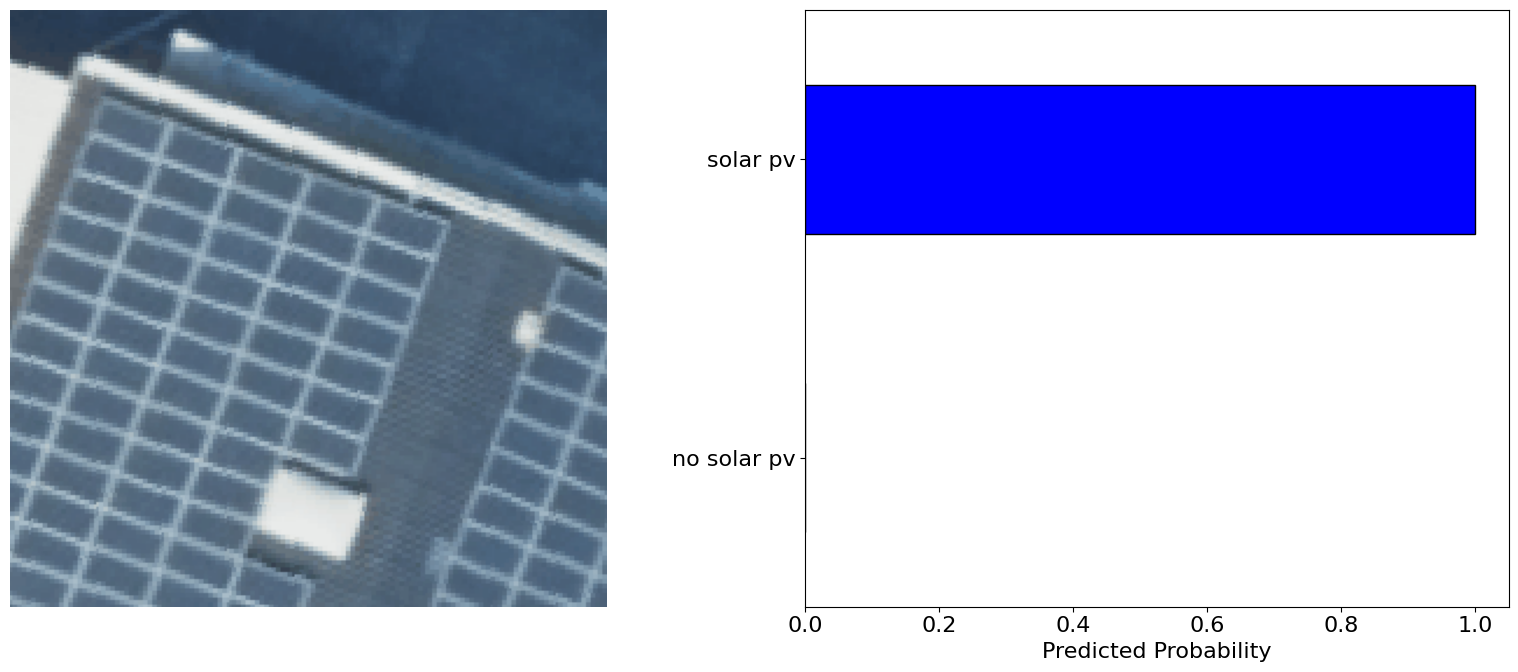

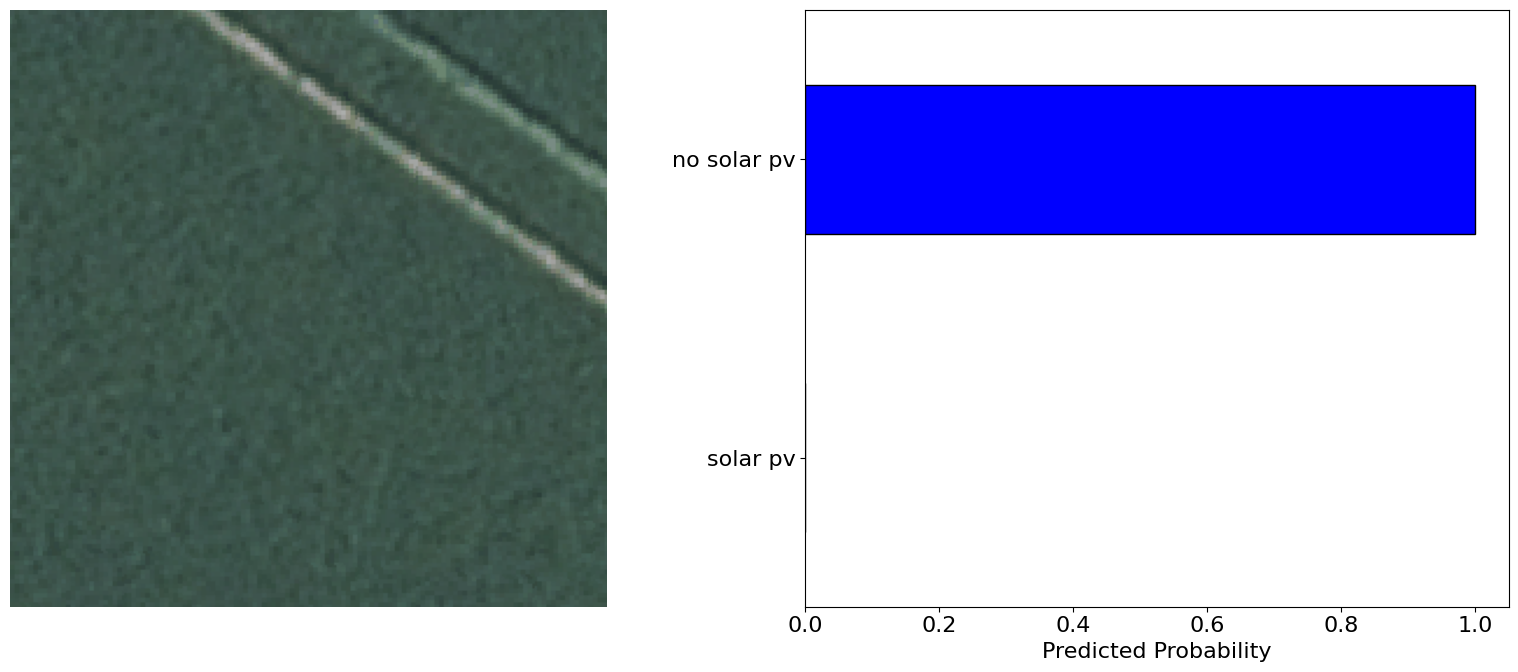

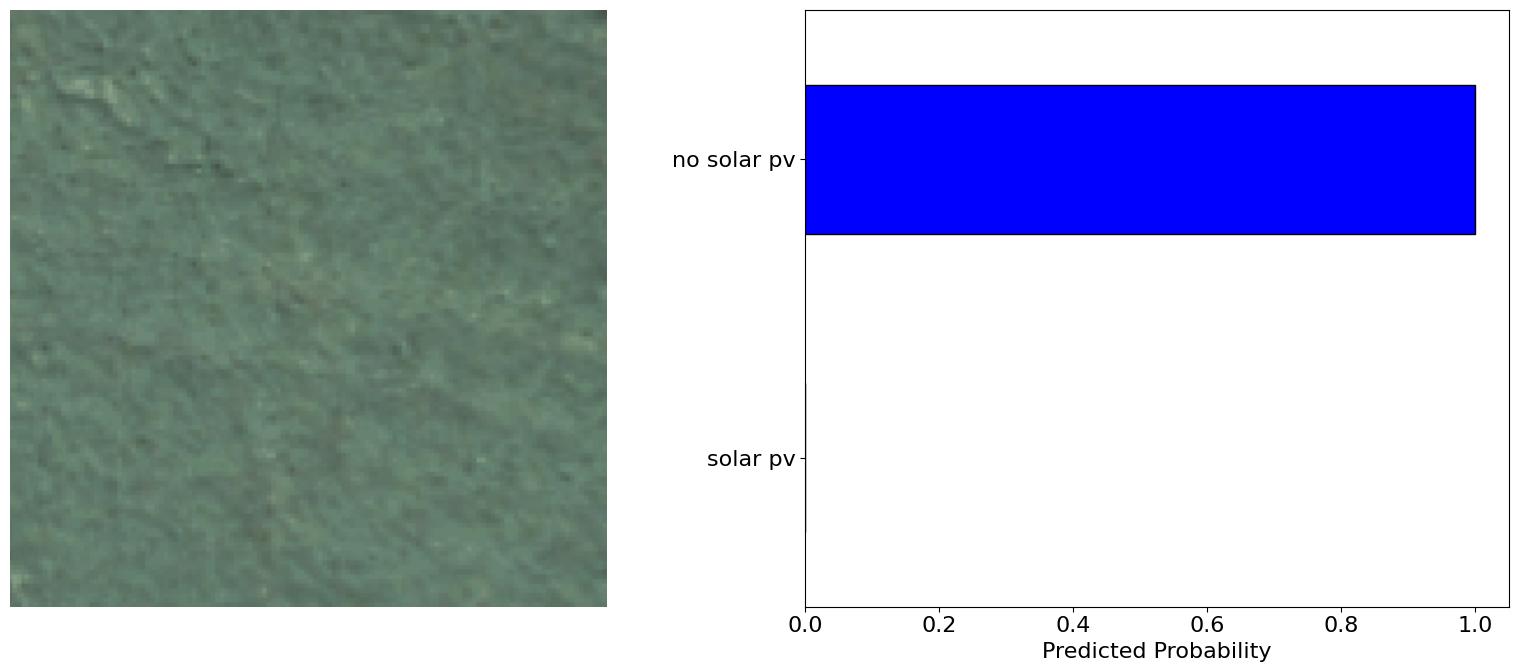

In [19]:
labels = ["no solar pv","solar pv"]
transform = ResizeCenterCropToTensor()

model_path = "/home/dragik/data/FAIR_EO/experiments/m_pv4ger/checkpoint.pth.tar"
model.load_model(model_path)

test_dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/m_pv4ger/data/classification_v0.8.1/pv4ger_classification",
    "csv_file": "/home/dragik/data/FAIR_EO/m_pv4ger/label_map.json",
    "mode": "test"
}
test_dataset = mPv4gerDataset(test_dataset_config)

image = test_dataset[0][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_image(image, labels, transform)